URL = https://github.com/BiomedicalMachineLearning/stLearn

In [1]:
# !pip install stlearn scanpy anndata pandas numpy scipy matplotlib

In [2]:
from pathlib import Path
import numpy as np
import scanpy as sc
import stlearn as st
import matplotlib.pyplot as plt

In [3]:
BASE = Path("../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1/STI_results")
# DATA_DIR = "../../Dataset/MERFISH/mouse_brain_map/Slice1/Replicate1"
OUT = BASE / "stLearn"
OUT.mkdir(parents=True, exist_ok=True)

adata = sc.read_h5ad(BASE / "S1R1_prepared.h5ad")

# SpaceFlow should receive the original count matrix here.
adata.X = adata.layers["counts"].copy()

In [4]:
# stLearn can perform expression-based trajectory inference
# without using the microscopy images.
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(
    adata, n_top_genes=min(2000, adata.n_vars), flavor="seurat"
)
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=min(30, adata.n_vars - 1))
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.leiden(adata, resolution=0.5, key_added="leiden")

print("Available clusters:", adata.obs["leiden"].value_counts().to_dict())

/usr/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
I0000 00:00:1792912178.918862 3104505 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792912178.952817 3104505 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792912180.053035 3104505 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environ

Available clusters: {'0': 11666, '1': 11357, '2': 9026, '3': 6728, '4': 5941, '5': 4560, '6': 3871, '7': 3574, '8': 3522, '9': 3136, '10': 2948, '11': 2920, '12': 2592, '13': 2195, '14': 1840, '15': 1836, '16': 411, '17': 206}


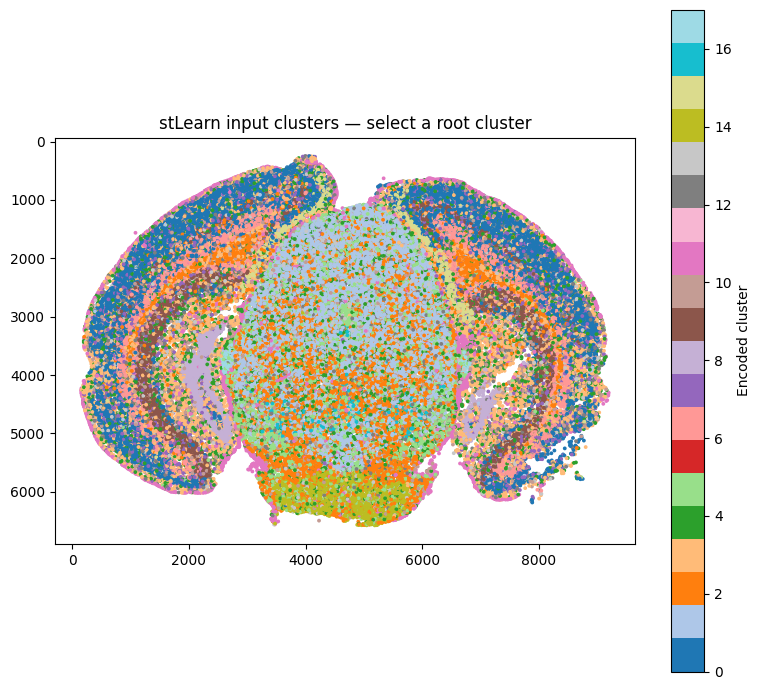

In [ ]:
# Plot clusters in actual tissue coordinates to help choose a root.
xy = adata.obsm["spatial"]
fig, ax = plt.subplots(figsize=(8, 7))
scatter = ax.scatter(
    xy[:, 0], xy[:, 1],
    c=adata.obs["leiden"].astype("category").cat.codes,
    s=3, cmap="tab20"
)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("stLearn input clusters — select a root cluster")
fig.colorbar(scatter, ax=ax, label="Encoded cluster")
fig.tight_layout()
fig.savefig(OUT / "01_clusters.png", dpi=200)
plt.show()


In [6]:
# IMPORTANT: change this after examining the cluster plot.
ROOT_CLUSTER = "0"

if ROOT_CLUSTER not in adata.obs["leiden"].astype(str).values:
    raise ValueError("ROOT_CLUSTER not present in the Leiden labels.")

# stLearn's set_root selects a root cell from the specified cluster.
adata.uns["iroot"] = st.spatial.trajectory.set_root(
    adata,
    use_label="leiden",
    cluster=ROOT_CLUSTER,
    use_raw=False,
)

/home/user/Gagan_env/genomicsProject/.genomicsProjectENV/lib/python3.10/site-packages/stlearn/spatial/trajectory/set_root.py:53: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  tmp_adata.var["gene_corr"] = gene_corr


In [7]:
# eps is in the coordinate units used by the method's spatial workflow.
# Start with a conservative value and tune to your coordinate scale.
st.spatial.trajectory.pseudotime(
    adata,
    use_label="leiden",
    eps=20,
    n_neighbors=25,
    use_rep="X_pca",
    pseudotime_key="dpt_pseudotime",
)

KeyError: "None of [Index(['imagerow', 'imagecol'], dtype='object')] are in the [columns]"

In [ ]:
# Save the cell-level pseudotime.
adata.obs.to_csv(OUT / "cell_results.csv")
adata.write_h5ad(OUT / "stlearn_results.h5ad")

In [ ]:
# Plot pseudotime directly on the tissue coordinates.
pt = adata.obs["dpt_pseudotime"].to_numpy()
fig, ax = plt.subplots(figsize=(8, 7))
scat = ax.scatter(xy[:, 0], xy[:, 1], c=pt, s=3, cmap="viridis")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("stLearn pseudotime — S1R1")
fig.colorbar(scat, ax=ax, label="Pseudotime")
fig.tight_layout()
fig.savefig(OUT / "02_pseudotime.png", dpi=200)
plt.show()

print("stLearn results saved to:", OUT)
